# Milestone 2: exploratory data analysis and preprocessing

Group 2, Socratic AI Tutor. This notebook looks at every dataset we prepared, shows sample records, and explains
**what** each preprocessing step does and **why** it was chosen. It reads the prepared files; it does not rebuild them.

| Data | Prepared by | Where |
|---|---|---|
| ASSISTments learner-model arrays | Hariom Pandey | `notes/hariom pandey/milestone-2/dkt_processed/` |
| Chat corpus (MathDial + SocraTeach) | Hariom Pandey | `notes/hariom pandey/milestone-2/socratic_tutor_combined.jsonl` |
| Validation splits derived from the two above | Sandeep Nalla | `notes/sandeep/milestone-2/hosted_dataset/splits/` |
| NCERT text, course packs, test scenarios | Sandeep Nalla | `notes/sandeep/milestone-2/data/` |

The same files are in the hosted Google Drive folder (link in the report). NCERT text is not redistributed, so the NCERT, course-pack
and scenario cells need a local rebuild (`notes/sandeep/milestone-2/data/README.md`). Run this notebook from `docs/milestone-2/`.

In [1]:
import json
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (7, 3.4), "axes.spines.top": False, "axes.spines.right": False})
B = Path("../../notes/hariom pandey/milestone-2")
SPLITS = Path("../../notes/sandeep/milestone-2/hosted_dataset/splits")
A = Path("../../notes/sandeep/milestone-2/data")
P = A / "processed"

def jsonl(path):
    with open(path, encoding="utf8") as f:
        return [json.loads(line) for line in f]

## 1. ASSISTments (learner model)

**What it is.** One row per answer: which student, which skill, right or wrong on the first try. We use it to train the learner model
(DKT) that predicts the chance of a correct answer on each skill. Source: ASSISTments 2009-2010 skill-builder file, 303,260 rows.

**Preprocessing and why**

| Step | Why |
|---|---|
| Keep 4 columns (student, order, skill, correct) | Other columns (teacher, school, class) do not describe what the student knows, and the live tutor will not have them. |
| Drop 1 row with missing values and 46,668 exact duplicates (same student, order, skill) | Duplicates would count one answer several times. |
| Drop students with fewer than 3 answers | Too little history to learn from. |
| Number skills 0..81 and encode each answer as `x = skill + 82 x correct` | One input token carries both skill and result: the usual input for an embedding-based DKT. |
| Keep questions with several skills as separate steps | Standard DKT practice; the cost is that one answer can count as several steps. |
| Cut long histories into chunks of 200, drop chunks under 3 steps, pad with zeros and add a mask | Fixed-size batches. Cutting at 200 would lose about 27% of the rows. The mask makes the model ignore padding. |
| Split **by student** (80% train, 20% test, seed 42) | If a student were in two splits, the model could memorise them and the test score would be too high. |
| Validation: 10% of the train students (seed 42) | The prepared file has none; we list the validation rows in `splits/dkt_validation.json` and leave his files unchanged. |

In [2]:
d = np.load(B / "dkt_processed/dkt_data.npz")
N = int(d["N"])
val = json.load(open(SPLITS / "dkt_validation.json"))
val_idx = np.array(val["validation_train_sequence_indices"])
mask_tr = d["M_tr"] == 1
is_val = np.zeros(len(d["M_tr"]), bool); is_val[val_idx] = True

def row(name, X, M, C, S, students=None):
    return {"split": name, "sequences": len(M), "answers": int(M.sum()), "correct_rate": round(float(C[M].mean()), 3),
            "skills_used": len(np.unique(S[M]))}
rows = [row("train (as prepared)", None, mask_tr, d["C_tr"], d["S_tr"]),
        row("  of which training", None, mask_tr[~is_val], d["C_tr"][~is_val], d["S_tr"][~is_val]),
        row("  of which validation", None, mask_tr[is_val], d["C_tr"][is_val], d["S_tr"][is_val]),
        row("test", None, d["M_te"] == 1, d["C_te"], d["S_te"])]
print("skills (N):", N, "| input vocabulary:", 2 * N, "| validation students:", val["validation_students"], "of", val["train_students"])
pd.DataFrame(rows)

skills (N): 82 | input vocabulary: 164 | validation students: 273 of 2726


,split,sequences,answers,correct_rate,skills_used
0,train (as prepared),3168,205418,0.657,82
1,of which training,2848,183648,0.659,82
2,of which validation,320,21770,0.644,80
3,test,781,50642,0.644,80


In [3]:
steps = pd.read_csv(B / "dkt_processed/dkt_processed_steps.csv")
print("First rows of dkt_processed_steps.csv:"); print(steps.head(6).to_string(index=False))
for s, key in (("train", "tr"), ("test", "te")):
    M = d[f"M_{key}"] == 1
    assert bool((d[f"X_{key}"][M] == d[f"S_{key}"][M] + N * d[f"C_{key}"][M]).all()), "encoding broken"
print("encoding x = skill + N*correct holds for every real step")
users = steps.groupby("split").user_id.agg(set)
print("students in both train and test:", len(users["train"] & users["test"]))

First rows of dkt_processed_steps.csv:
split  user_id  chunk_id  step  skill_index  correct  x  skill_id_original
train    80959         0     0            8        0  8                 12
train    80959         0     1            9        1 91                 13
train    80959         0     2            9        1 91                 13
train    80959         0     3            9        0  9                 13
train    80959         0     4            8        0  8                 12
train    80959         0     5            8        0  8                 12
encoding x = skill + N*correct holds for every real step


students in both train and test: 0


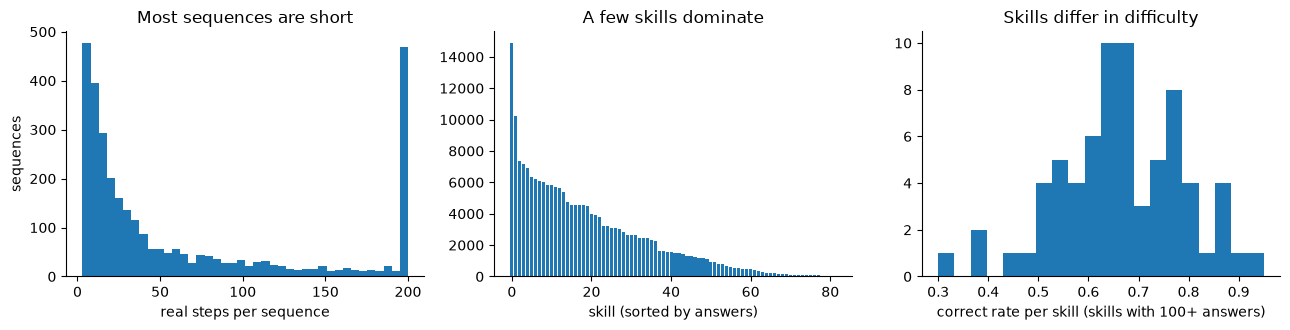

median sequence length: 29 | at the 200 cap: 14.3%
skills with fewer than 100 train answers: 11 of 82 | most practised skill: 14880 answers


In [4]:
L = d["M_tr"].sum(axis=1)
cnt = np.bincount(d["S_tr"][mask_tr], minlength=N)
cor = np.bincount(d["S_tr"][mask_tr], weights=d["C_tr"][mask_tr], minlength=N)
rate = cor / np.maximum(cnt, 1)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].hist(L, bins=40); ax[0].set_xlabel("real steps per sequence"); ax[0].set_ylabel("sequences"); ax[0].set_title("Most sequences are short")
ax[1].bar(range(N), np.sort(cnt)[::-1]); ax[1].set_xlabel("skill (sorted by answers)"); ax[1].set_title("A few skills dominate")
ax[2].hist(rate[cnt >= 100], bins=20); ax[2].set_xlabel("correct rate per skill (skills with 100+ answers)"); ax[2].set_title("Skills differ in difficulty")
plt.tight_layout(); plt.show()
print("median sequence length: %d | at the 200 cap: %.1f%%" % (np.median(L), 100 * (L == 200).mean()))
print("skills with fewer than 100 train answers:", int((cnt < 100).sum()), "of", N, "| most practised skill:", int(cnt.max()), "answers")

**Reading it.** The most practised skill has about 15,000 answers while 11 of 82 skills have fewer than 100, so a DKT model will be far more
reliable on common skills and results should be reported per skill, not only as one AUC. Per-skill correct rates vary widely, so skill identity
alone already predicts a lot: a per-skill accuracy baseline is the first thing the learned model must beat. The test set uses 80 of the 82 skills.

## 2. Chat corpus: MathDial and SocraTeach (Socratic model)

**MathDial** (2,861 dialogues, 2,262 in the train split used here): a teacher guides a simulated student who made a mistake on a maths word problem.
**SocraTeach Multi** (10,273 problems, 35,151 dialogues): Socratic tutoring dialogues with simulated student types.
Each dialogue is one record with a `messages` list (system, assistant, user).

**Preprocessing and why**

| Step | Why |
|---|---|
| SocraTeach: expand each problem into its dialogues; tutor text becomes `assistant`, student reply becomes `user` | Chat format is what the fine-tuning tools read; one dialogue is the natural training unit. |
| MathDial: keep system/assistant/user messages, trim whitespace, remove 4 empty messages | Empty messages add noise; the system message carries the problem and the tutor instructions. |
| Hold out MathDial's 599 test conversations | Results stay comparable with the paper. |
| Add a `source` tag and merge | Lets us train on one source or both and trace each record. |
| Validation: 10% of MathDial problems (seed 42) | Split **by problem**: several dialogues share one problem, so a random cut would put near-identical conversations on both sides. SocraTeach has no problem text in its messages, so it cannot be grouped and stays in train. |

In [5]:
roles, src, first, turns = Counter(), Counter(), Counter(), {"mathdial": [], "soctrateach": []}
with open(B / "socratic_tutor_combined.jsonl", encoding="utf8") as f:
    for line in f:
        r = json.loads(line); src[r["source"]] += 1
        first[(r["source"], r["messages"][0]["role"])] += 1
        turns[r["source"]].append(len(r["messages"]))
        for m in r["messages"]: roles[(r["source"], m["role"])] += 1
cv = json.load(open(SPLITS / "chat_validation.json"))
print("conversations:", dict(src), "| total", sum(src.values()))
print(pd.Series(roles).unstack(fill_value=0))
print("first role of each conversation:", dict(first))
print("validation:", cv["validation_conversations"], "MathDial conversations from", cv["validation_problems"], "of", cv["mathdial_problems"], "problems; train:", sum(src.values()) - cv["validation_conversations"])

conversations: {'soctrateach': 35151, 'mathdial': 2262} | total 37413
             assistant  system    user
mathdial         14448    2262   13410
soctrateach     185600       0  150451
first role of each conversation: {('soctrateach', 'assistant'): 35151, ('mathdial', 'system'): 2262}
validation: 215 MathDial conversations from 104 of 1035 problems; train: 37198


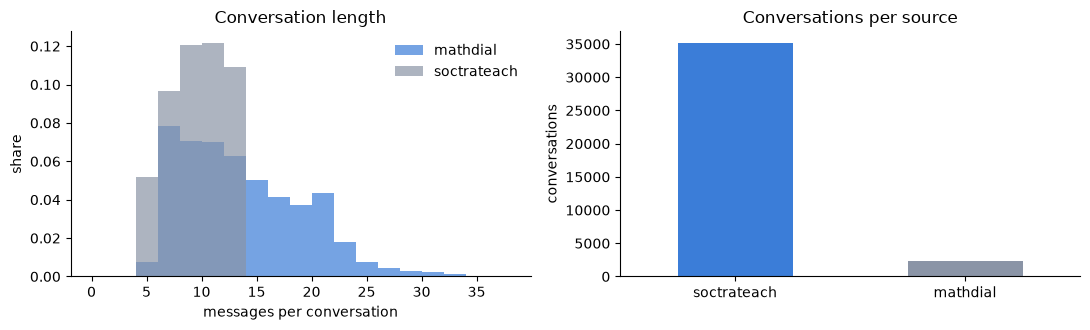

[soctrateach] [('assistant', 'How many clips did Natalia sell in May?'), ('user', 'I\'m confused. Does "half as many" mean the same number as April?'), ('assistant', 'Not exactly, "half as many" means half the amount. If Natalia sold 48 clips in April, what would be half of 48')]

[mathdial] [('system', 'You are a friendly and supportive teacher.\nThe student is trying to solve the following problem: Nancy is fill'), ('assistant', 'Steven, If you had 4 of something and tripled that amount, how much would you have?'), ('user', 'I would have 12 of something.')]



In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for name, color in (("mathdial", "#3b7dd8"), ("soctrateach", "#8a94a6")):
    ax[0].hist(turns[name], bins=range(0, 40, 2), alpha=0.7, label=name, color=color, density=True)
ax[0].set_xlabel("messages per conversation"); ax[0].set_ylabel("share"); ax[0].legend(frameon=False); ax[0].set_title("Conversation length")
pd.Series(src).plot.bar(ax=ax[1], rot=0, color=["#3b7dd8", "#8a94a6"]); ax[1].set_title("Conversations per source"); ax[1].set_ylabel("conversations")
plt.tight_layout(); plt.show()
recs = {}
with open(B / "socratic_tutor_combined.jsonl", encoding="utf8") as f:
    for line in f:
        r = json.loads(line)
        recs.setdefault(r["source"], r)
        if len(recs) == 2: break
recs = list(recs.values())
for r in recs:
    print(f"[{r['source']}]", [(m["role"], m["content"][:110]) for m in r["messages"][:3]]); print()

**Reading it.** SocraTeach is 94% of the conversations but its conversations are shorter (about 10 messages against 13 for MathDial), while MathDial is closer to our target (a student with
a wrong solution). A model trained on the mix may lean toward SocraTeach's style, so we may weight or filter. No reply is flagged as "telling the answer",
so a model trained on this file can learn to give answers away: first thing to add. MathDial's 2,262 conversations are all train-split conversations;
the 599 test conversations are not in the file.

## 3. NCERT text (study material for search)

Maths and Science, classes 6-10, from ncert.nic.in. The text is not redistributed (the books are public but not ours to republish), so
only counts and a short excerpt are shown.

**Preprocessing and why**

| Step | Why |
|---|---|
| Extract text page by page | Keeps the page number so the tutor can cite "chapter X, page Y". |
| Clean headers, footers and stray characters | They add noise to search. |
| Split into chunks of up to 250 words | Small enough to retrieve precisely, large enough to hold one idea. |
| Tag each chunk with subject, class, chapter, page | Needed for citations and to filter by level. |

In [7]:
ncert = json.load(open(P / "ncert/stats.json"))
books = pd.DataFrame(ncert["books"]).T
books.index.name = "book"
print("chunks:", ncert["chunks"], "| pages:", ncert["pages"], "| kept:", ncert["pages_kept"], "| failed:", ncert["pages_failed"])
books

chunks: 3164 | pages: 2401 | kept: 2353 | failed: 4


,chapters,chunks
book,,
maths_class10,14,253
maths_class6,10,475
maths_class7,8,369
maths_class8,13,213
maths_class9,8,301
science_class10,13,217
science_class6,12,345
science_class7,12,330
science_class8,13,181


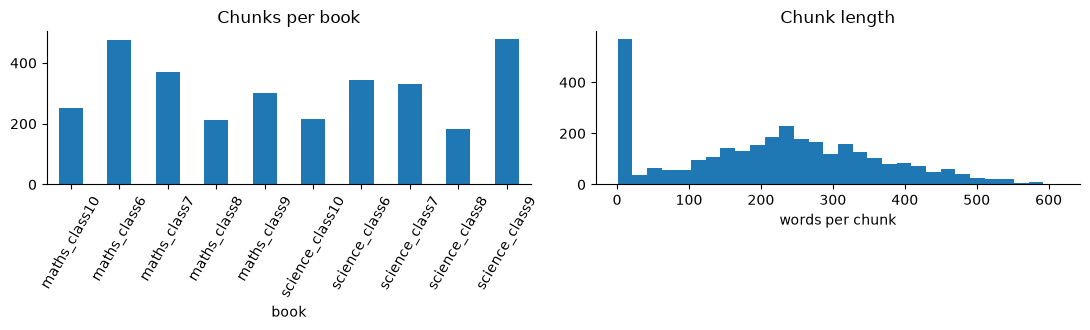

Sample chunk fields: {'id': 'ncert-maths-10-06-p017-0', 'course': 'ncert-maths', 'subject': 'maths', 'class': 10, 'level': 10, 'chapter': 6, 'page': 17, 'source': 'NCERT Maths Class 10, chapter 6', 'text': 'TRIANGLES 89 Fig. 6.26 Cut DP = AB and DQ = AC and join PQ. It can be seen that DPPE = DQQF and PQ || EF (How?) So, \uf0d0 P = \uf0d0 E and \uf0d0 Q = \uf0d0 F. Therefore, DPDE = D...'}
share of chunks under 50 words: 20.2%


In [8]:
chunks = jsonl(P / "ncert/chunks.jsonl")
wc = pd.Series([len(c["text"].split()) for c in chunks])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
books["chunks"].plot.bar(ax=ax[0], rot=60); ax[0].set_title("Chunks per book")
ax[1].hist(wc, bins=30); ax[1].set_xlabel("words per chunk"); ax[1].set_title("Chunk length")
plt.tight_layout(); plt.show()
c = chunks[100]
print("Sample chunk fields:", {k: (v if k != "text" else v[:160] + "...") for k, v in c.items()})
print("share of chunks under 50 words: %.1f%%" % (100 * (wc < 50).mean()))

**Reading it.** About 20% of chunks are under 50 words (chapter ends, figure captions). The sample chunk above shows the main known problem:
older Class 8-10 maths books lose symbols and digits in extraction (stray characters, and `80/100` reading `80100`). Those books need a manual
check before being used for search; the course packs lean on the Class 6-7 books but also use Class 8.

## 4. Course packs and our own test scenarios

Hand-written by the team (not downloaded). Packs hold concepts, prerequisite links and practice questions. The scenarios test the tutor's
decisions and are never used for training.

               prerequisites  questions  concepts
pack                                             
ncert-maths               13         52        10
ncert-science              6         18         6


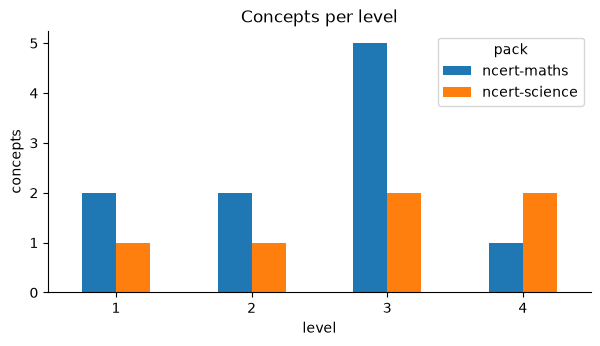

In [9]:
rows = []
for name in ("ncert-maths", "ncert-science"):
    pack = json.load(open(P / f"course_packs/{name}.json", encoding="utf8"))
    for c in pack["concepts"]:
        rows.append({"pack": name, "concept": c["id"], "level": c["level"], "prerequisites": len(c["prerequisites"]),
                     "questions": len(c["questions"]), "materials": len(c["materials"])})
packs = pd.DataFrame(rows)
print(packs.groupby("pack")[["prerequisites", "questions"]].sum().assign(concepts=packs.groupby("pack").size()))
packs.groupby(["pack", "level"]).size().unstack(0).fillna(0).astype(int).plot.bar(rot=0, title="Concepts per level")
plt.ylabel("concepts"); plt.show()

In [10]:
S = A / "test_scenarios"
bt, mc, gr = (jsonl(S / f"{n}.jsonl") for n in ("backtracking", "misconceptions", "guardrails"))
print("backtracking:", dict(Counter(r["type"] for r in bt)))
print("guardrails  :", dict(Counter(r["label"] for r in gr)))
print("misconceptions:", len(mc), "items,", len({r["misconception"] for r in mc}), "kinds")
print()
for r in (bt[1], bt[2]):
    print({k: r[k] for k in ("type", "learner_answer", "weak_concepts", "mastery", "expected_first_action")})
print("-> same answer, different mastery, so different first action (probe vs hint)")
print(); print(mc[0]); print(); print(gr[25])

backtracking: {'correct': 16, 'careless_mistake': 16, 'success_after_hint': 16, 'gap_one_level': 19, 'gap_two_levels': 15}
guardrails  : {'on_topic': 15, 'off_topic': 15, 'answer_request': 17}
misconceptions: 32 items, 24 kinds

{'type': 'careless_mistake', 'learner_answer': '121', 'weak_concepts': [], 'mastery': {'multiplication_division': 0.9}, 'expected_first_action': 'probe'}
{'type': 'success_after_hint', 'learner_answer': '121', 'weak_concepts': [], 'mastery': {'multiplication_division': 0.5}, 'expected_first_action': 'hint'}
-> same answer, different mastery, so different first action (probe vs hint)

{'id': 'mc-001', 'course': 'ncert-maths', 'concept': 'percentages', 'question': 'What is 20% of 50?', 'correct_answer': '10', 'wrong_answer': '2.5', 'misconception': 'divides_by_the_percent', 'explanation': 'Divided 50 by 20 instead of finding 20/100 of 50.', 'reviewed_by': None}

{'id': 'gr-026', 'course': 'ncert-science', 'current_concept': 'time_and_speed', 'message': 'What is t

**Why scenarios carry `mastery`.** A slip (wrong answer, high mastery) should get a probe; a real shaky spot (wrong answer, middling mastery) a hint;
a weak prerequisite a backtrack. Without the mastery estimate two of these cases would have identical inputs and different labels, so no tutor could score on both.
The data check `check_data.py` enforces "same inputs, same label".

## 5. Summary of what the EDA tells us

- **Learner model:** heavily skewed skills, so report per-skill results and compare with a per-skill accuracy baseline. Splits are by student, validation included.
- **Socratic model:** the chat corpus is mostly SocraTeach and has no marking of answer-giving replies; add that flag before fine-tuning. Validation is by problem.
- **Study text:** chunked with citations; older books need manual repair.
- **Evaluation:** our scenarios are small (161 items) and written by us, so they test logic, not real learners.